# 07 — Perbandingan Baseline vs SMOTE-ENN (XGBoost & LightGBM)

Notebook ini membandingkan **4 kombinasi**:

1. XGBoost baseline (tanpa resampling)
2. XGBoost + SMOTE-ENN (tuned)
3. LightGBM baseline (tanpa resampling)
4. LightGBM + SMOTE-ENN (tuned)

Output: tabel perbandingan, confusion matrix, ROC curve overlay, dan bar chart
waktu training.

> **PENTING (catatan interpretasi):** jangan memilih model "terbaik" hanya dari
> **accuracy**. Untuk kasus kesehatan dengan kelas tidak seimbang, fokus pada
> **Recall** dan **F1-Score kelas `Stunted`** karena false negative (balita stunting
> terprediksi normal) berakibat fatal: anak tidak mendapat intervensi gizi dini.

> **Keterangan teknis:** metrik final dibaca dari `baseline_results.csv` dan
> `smoteenn_results.csv` (hasil notebook 04 & 06). Karena probabilitas prediksi dan
> waktu training belum tersimpan di CSV, model di-*refitting* dengan konfigurasi
> **identik** di notebook ini untuk menghasilkan kurva ROC & pengukuran waktu,
> lalu diverifikasi cocok dengan CSV.

In [1]:
import os
import time
import pandas as pd
import numpy as np
from joblib import load
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = "../data/processed"
METRICS_DIR = "../results/metrics"
LABELS = ["Not Stunted", "Stunted"]
POS_LABEL = 1

In [2]:
base = pd.read_csv(os.path.join(METRICS_DIR, "baseline_results.csv"))
base["scenario"] = "baseline"

sme = pd.read_csv(os.path.join(METRICS_DIR, "smoteenn_results.csv"))
sme["scenario"] = "SMOTE-ENN"

combined = pd.concat([base, sme], ignore_index=True)
combined["label"] = combined["model"] + " + " + combined["scenario"]
combined

,model,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp,scenario,label
0,XGBoost,0.959191,0.958163,0.940123,0.949057,0.992883,4640,133,194,3046,baseline,XGBoost + baseline
1,LightGBM,0.960938,0.957487,0.945370,0.951390,0.993038,4637,136,177,3063,baseline,LightGBM + baseline
2,XGBoost,0.956071,0.945954,0.945370,0.945662,0.990805,4598,175,177,3063,SMOTE-ENN,XGBoost + SMOTE-ENN
3,LightGBM,0.955697,0.941537,0.949383,0.945443,0.990885,4582,191,164,3076,SMOTE-ENN,LightGBM + SMOTE-ENN


In [3]:
X_train = load(os.path.join(DATA_DIR, "X_train.joblib"))
y_train = load(os.path.join(DATA_DIR, "y_train.joblib"))
X_train_resampled = load(os.path.join(DATA_DIR, "X_train_resampled.joblib"))
y_train_resampled = load(os.path.join(DATA_DIR, "y_train_resampled.joblib"))
X_test = load(os.path.join(DATA_DIR, "X_test.joblib"))
y_test = load(os.path.join(DATA_DIR, "y_test.joblib"))

print("X_test", X_test.shape, "| y_test", y_test.shape)
print("Distribusi y_test:", np.bincount(np.asarray(y_test).astype(int)).tolist())

X_test (8013, 4) | y_test (8013,)
Distribusi y_test: [4773, 3240]


## 1. Refit 4 model (konfigurasi identik) + ukur waktu training

In [4]:
import json

with open(os.path.join(METRICS_DIR, "best_params.json")) as f:
    best_params = json.load(f)

configs = {
    "XGBoost + baseline": XGBClassifier(
        random_state=RANDOM_STATE, eval_metric="logloss", verbosity=0
    ),
    "XGBoost + SMOTE-ENN": XGBClassifier(
        random_state=RANDOM_STATE, eval_metric="logloss", verbosity=0,
        **best_params["XGBoost"],
    ),
    "LightGBM + baseline": LGBMClassifier(
        random_state=RANDOM_STATE, verbosity=-1
    ),
    "LightGBM + SMOTE-ENN": LGBMClassifier(
        random_state=RANDOM_STATE, verbosity=-1,
        **best_params["LightGBM"],
    ),
}

train_data = {
    "XGBoost + baseline": (X_train, y_train),
    "XGBoost + SMOTE-ENN": (X_train_resampled, y_train_resampled),
    "LightGBM + baseline": (X_train, y_train),
    "LightGBM + SMOTE-ENN": (X_train_resampled, y_train_resampled),
}

train_times = {}
preds = {}
probas = {}
recomputed = []

for label, model in configs.items():
    X_tr, y_tr = train_data[label]

    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_times[label] = time.perf_counter() - t0

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    preds[label] = y_pred
    probas[label] = y_proba

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    recomputed.append({
        "label": label,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, pos_label=POS_LABEL),
        "recall": recall_score(y_test, y_pred, pos_label=POS_LABEL),
        "f1_score": f1_score(y_test, y_pred, pos_label=POS_LABEL),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    })

recomputed_df = pd.DataFrame(recomputed)
print("Waktu training (detik):")
for k, v in train_times.items():
    print(f"  {k:22s} {v:.4f}s")

Waktu training (detik):
  XGBoost + baseline     1.5255s
  XGBoost + SMOTE-ENN    0.3196s
  LightGBM + baseline    1.4347s
  LightGBM + SMOTE-ENN   0.2776s


## 2. Verifikasi metrik recomputed cocok dengan CSV

In [5]:
check = combined.merge(
    recomputed_df[["label", "recall", "f1_score", "roc_auc"]],
    on="label", suffixes=("_csv", "_re"),
)
check["recall_ok"] = np.isclose(check["recall_csv"], check["recall_re"])
check["f1_ok"] = np.isclose(check["f1_score_csv"], check["f1_score_re"])
check["auc_ok"] = np.isclose(check["roc_auc_csv"], check["roc_auc_re"])

print(check[["label", "recall_ok", "f1_ok", "auc_ok"]])
assert check[["recall_ok", "f1_ok", "auc_ok"]].all().all(), \
    "Metrik recomputed tidak cocok dengan CSV — cek konfigurasi model!"
print("OK: metrik recomputed konsisten dengan CSV.")

                  label  recall_ok  f1_ok  auc_ok
0    XGBoost + baseline       True   True    True
1   LightGBM + baseline       True   True    True
2   XGBoost + SMOTE-ENN       True   True    True
3  LightGBM + SMOTE-ENN       True   True    True
OK: metrik recomputed konsisten dengan CSV.


## 3. Tabel Perbandingan 4 Kombinasi

In [6]:
tt = pd.DataFrame({
    "label": list(train_times.keys()),
    "train_time_s": list(train_times.values()),
})

comparison = combined.merge(tt, on="label")

table = comparison[[
    "label", "accuracy", "precision", "recall", "f1_score", "roc_auc", "train_time_s"
]].copy()
table.columns = [
    "Kombinasi", "Accuracy", "Precision", "Recall (Stunted)", "F1 (Stunted)", "ROC-AUC", "Train time (s)"
]
table.round(4)

,Kombinasi,Accuracy,Precision,Recall (Stunted),F1 (Stunted),ROC-AUC,Train time (s)
0,XGBoost + baseline,0.9592,0.9582,0.9401,0.9491,0.9929,1.5255
1,LightGBM + baseline,0.9609,0.9575,0.9454,0.9514,0.9930,1.4347
2,XGBoost + SMOTE-ENN,0.9561,0.9460,0.9454,0.9457,0.9908,0.3196
3,LightGBM + SMOTE-ENN,0.9557,0.9415,0.9494,0.9454,0.9909,0.2776


## 4. Confusion Matrix (4 kombinasi)

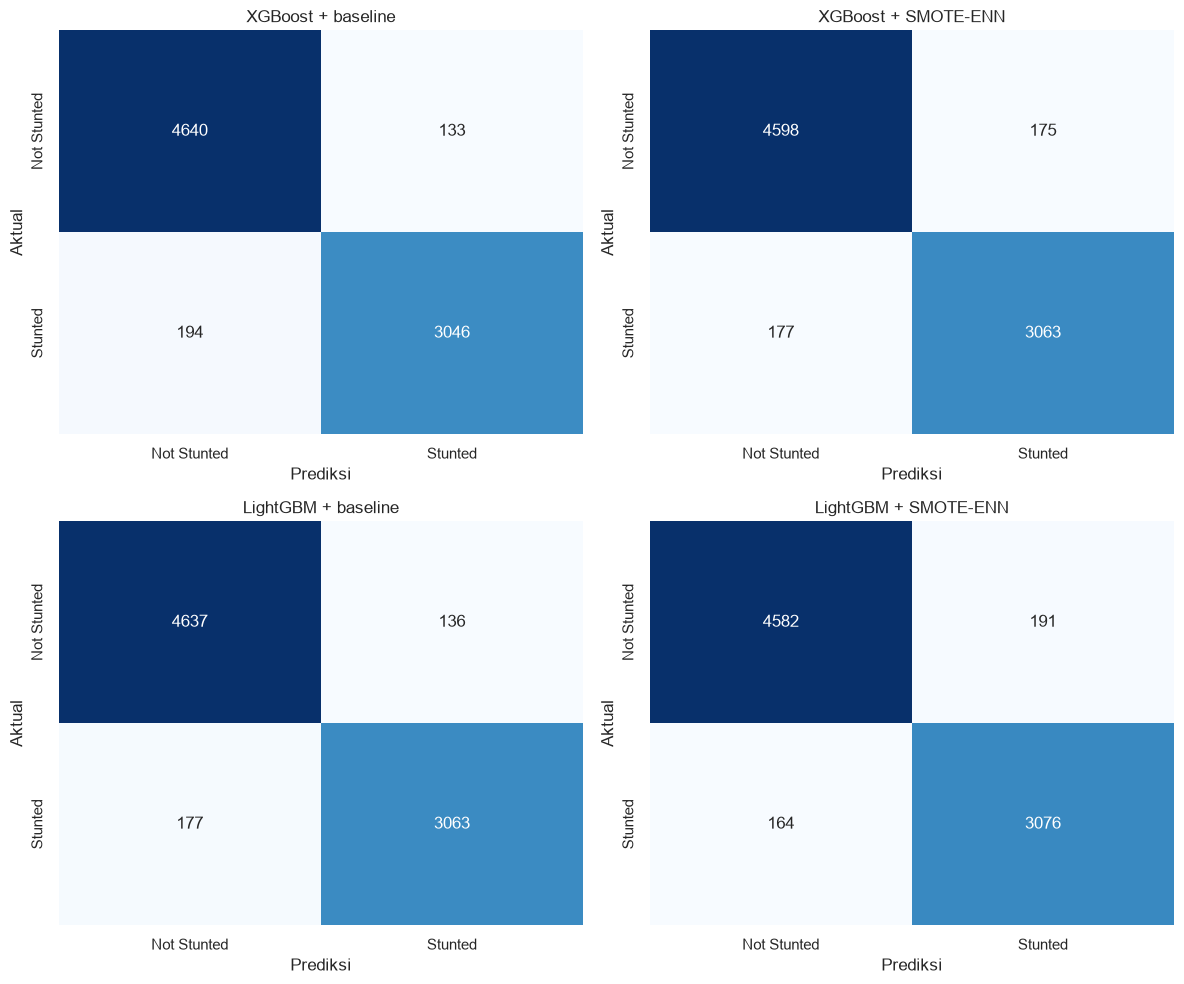

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, label in zip(axes.ravel(), configs.keys()):
    cm = confusion_matrix(y_test, preds[label], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(label)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.show()

## 5. ROC Curve (overlay 4 model)

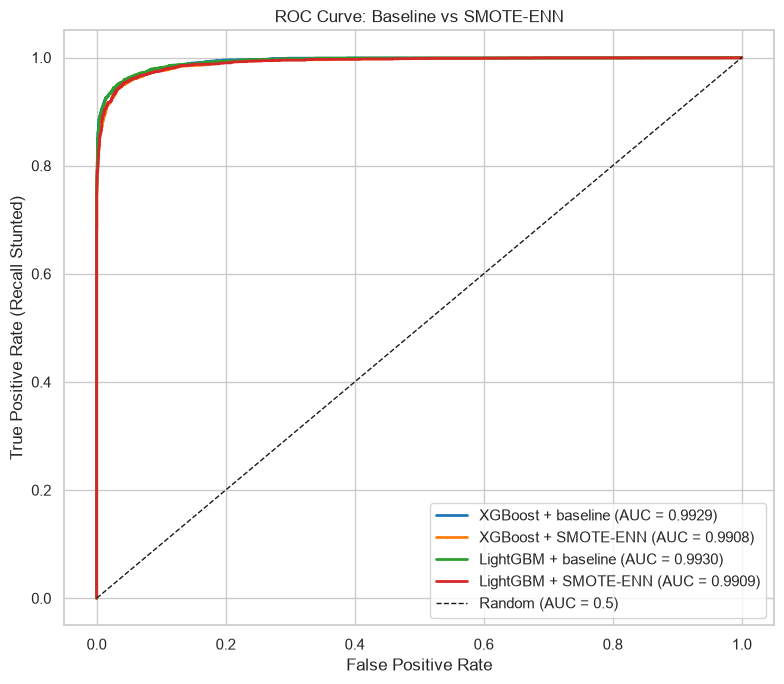

In [8]:
color_map = {
    "XGBoost + baseline": "tab:blue",
    "XGBoost + SMOTE-ENN": "tab:orange",
    "LightGBM + baseline": "tab:green",
    "LightGBM + SMOTE-ENN": "tab:red",
}

plt.figure(figsize=(8, 7))
for label in configs.keys():
    fpr, tpr, _ = roc_curve(y_test, probas[label], pos_label=POS_LABEL)
    auc = roc_auc_score(y_test, probas[label])
    plt.plot(fpr, tpr, color=color_map[label], lw=2,
             label=f"{label} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall Stunted)")
plt.title("ROC Curve: Baseline vs SMOTE-ENN")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Bar Chart Waktu Training

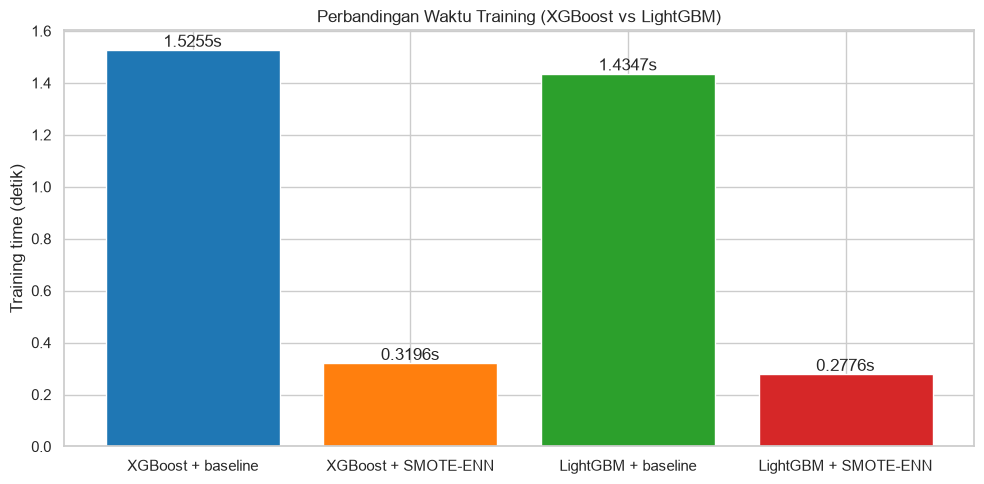

In [9]:
labels_order = list(configs.keys())
times_order = [train_times[l] for l in labels_order]
colors = [color_map[l] for l in labels_order]

plt.figure(figsize=(10, 5))
bars = plt.bar(labels_order, times_order, color=colors)
for bar, t in zip(bars, times_order):
    plt.annotate(f"{t:.4f}s", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 ha="center", va="bottom")
plt.ylabel("Training time (detik)")
plt.title("Perbandingan Waktu Training (XGBoost vs LightGBM)")
plt.tight_layout()
plt.show()

## Panduan Interpretasi (fokus Recall & F1 kelas Stunted)

- **Recall (Stunted)** = proporsi balita *stunting* yang berhasil dideteksi model.
  Nilai rendah → banyak *false negative* → anak stunting terlewat intervensi. Ini
  adalah metrik yang paling penting di penelitian ini.
- **Precision (Stunted)** = ketepatan saat model memprediksi *stunting* (menekan
  *false positive*).
- **F1 (Stunted)** = rata-rata harmonik precision & recall; dipakai sebagai tolok ukur
  keberhasilan SMOTE-ENN dalam menyeimbangkan deteksi kelas minoritas.
- **Jangan** menyimpulkan model "terbaik" dari accuracy semata — accuracy bisa tinggi
  meski model gagal mendeteksi banyak kasus stunting (accuracy paradox).

Bandingkan recall/F1 kelas Stunted antara baseline vs SMOTE-ENN untuk tiap algoritma,
dan antara XGBoost vs LightGBM, serta pertimbangkan waktu training pada bar chart.